In [2]:
import numpy as np

In [5]:
nsw = 25; n = nsw+1; x = np.arange(n, dtype=float); rng = np.random.default_rng(1)
g = lambda A, x0, w: A*np.exp(-((x-x0)/w)**2)
P = [g(1500,24,4)+g(300,12,2.5), g(1500,1,4)+g(1500,24,4)+g(300,12,2.5), g(800,12,2.5)+np.where(x>18,900.,0.),
     np.array([-56.88,-44.72,-31.79,-19.91,-9.17,-14.90,-1.90,12.49,34.64,61.95,75.96,91.04,110.82,110.38,
               108.44,101.81,92.94,103.74,123.47,130.13,122.91,127.45,142.43,150.16,172.37,191.10])]
for k in range(500):
    p = np.zeros(n)
    for m in range(rng.integers(1,4)): p += g(rng.uniform(100,1500), rng.uniform(-3,n+2), rng.uniform(1.5,8))
    p += rng.normal(0, rng.uniform(0,40), n)
    if rng.random() < 0.1: p = np.linspace(0,500,n) + rng.normal(0,5,n)
    P.append(p)
P = np.array(P)
with open('profiles.txt','w') as f:
    f.write(f"{len(P)} {nsw}\n")
    for p in P: f.write(" ".join(f"{v:.8f}" for v in p)+"\n")
np.save('profiles.npy', P); print(len(P), 'profiles, nsw =', nsw)


504 profiles, nsw = 25


In [6]:
"""Compare wedges_f90.txt (from test_rnodes_v2) with the Python references."""
import numpy as np, collections
from rnodes import rnodes, classify
from rnodes_v2 import rnodes_v2
P = np.load('profiles.npy'); nsw = P.shape[1]-1; n = nsw+1
rows = [l.split() for l in open('wedges_f90.txt')]
F = np.array([[float(v) for v in r[:10]] for r in rows]); LOK = np.array([r[10]=='T' for r in rows])
bad_old = bad_new = 0
for k, p in enumerate(P):
    o = rnodes(p)
    w = rnodes_v2(np.arange(1,n+1), p, nnode=n, ns2=nsw//2, bound_at_higher=True, npts=3)
    if not np.array_equal(o['xwedge'], F[k,1:4].astype(int)): bad_old += 1; print('old mismatch', k, o['xwedge'], F[k,1:4])
    pyw = w['xwedge'] if w['ok'] else np.zeros(3, int)
    if not np.array_equal(pyw, F[k,4:7].astype(int)) or w['ok'] != LOK[k] or (w['ok'] and abs(w['rms']-F[k,9]) > 1e-4):
        bad_new += 1; print('v2 mismatch', k, pyw, F[k,4:7], w.get('rms'), F[k,9])
print(f"{len(P)} profiles: old rnodes mismatches={bad_old}, rnodes_v2 mismatches={bad_new}")
print('old-wedge classes:', collections.Counter(classify(rnodes(p)['xwedge']) for p in P))


504 profiles: old rnodes mismatches=0, rnodes_v2 mismatches=0
old-wedge classes: Counter({'ok': 237, 'right': 108, 'left': 64, 'both': 51, 'zero': 44})


In [7]:
import matplotlib.pyplot as plt

In [16]:
print( n )

26


In [15]:
print( F[1] )

[ 2.     13.     13.     13.      9.     13.     17.      7.     20.
 32.6693]


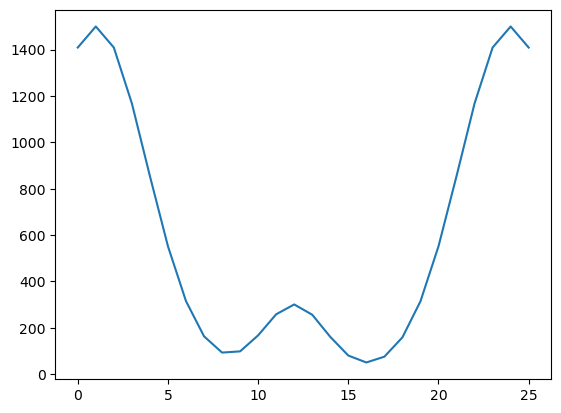

In [14]:
plt.plot( P[1] )

In [17]:
rr=P[1]
w = rnodes_v2(np.arange(1,n+1), rr, nnode=n, ns2=nsw//2, bound_at_higher=True, npts=3)


In [19]:
print( w['hwedge'] )

[ 93.34752451 300.96447673  50.66605219]
